In [1]:
import zipfile
import os
import glob
import pandas as pd

# Find the uploaded ZIP file
zip_files = glob.glob("/content/*.zip")
print(zip_files)

['/content/archive (1).zip']


In [2]:
zip_path = zip_files[0]
extract_path = "/content/ecommerce"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
csv_files = glob.glob(
    extract_path + "/**/*.csv",
    recursive=True
)

datasets = {}

for file in csv_files:
    name = os.path.basename(file).replace(".csv", "")
    datasets[name] = pd.read_csv(file)
    print(name, datasets[name].shape)

olist_products_dataset (32951, 9)
olist_orders_dataset (99441, 8)
olist_order_payments_dataset (103886, 5)
olist_geolocation_dataset (1000163, 5)
product_category_name_translation (71, 2)
olist_customers_dataset (99441, 5)
olist_sellers_dataset (3095, 4)
olist_order_reviews_dataset (99224, 7)
olist_order_items_dataset (112650, 7)


In [4]:
orders = datasets["olist_orders_dataset"]
customers = datasets["olist_customers_dataset"]
order_items = datasets["olist_order_items_dataset"]
payments = datasets["olist_order_payments_dataset"]
products = datasets["olist_products_dataset"]

print("Orders:", orders.shape)
print("Customers:", customers.shape)
print("Order items:", order_items.shape)

orders.head()

Orders: (99441, 8)
Customers: (99441, 5)
Order items: (112650, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
import pandas as pd

# Convert dates to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"],
    errors="coerce"
)

orders["order_estimated_delivery_date"] = pd.to_datetime(
    orders["order_estimated_delivery_date"],
    errors="coerce"
)

# Calculate main KPIs
total_orders = orders["order_id"].nunique()
unique_customers = customers["customer_unique_id"].nunique()
total_products_sold = len(order_items)
total_revenue = payments["payment_value"].sum()

delivered_orders = orders[
    orders["order_status"] == "delivered"
]

delivery_days = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

average_delivery_days = delivery_days.mean()

print("===== E-COMMERCE BUSINESS KPIs =====")
print("Total Orders:", f"{total_orders:,}")
print("Unique Customers:", f"{unique_customers:,}")
print("Order Item Records:", f"{total_products_sold:,}")
print("Total Payment Value: R$", f"{total_revenue:,.2f}")
print("Average Delivery Time (days):", round(average_delivery_days, 2))

===== E-COMMERCE BUSINESS KPIs =====
Total Orders: 99,441
Unique Customers: 96,096
Order Item Records: 112,650
Total Payment Value: R$ 16,008,872.12
Average Delivery Time (days): 12.56


     month  payment_value
0  2016-09         252.24
1  2016-10       59090.48
2  2016-12          19.62
3  2017-01      138488.04
4  2017-02      291908.01
5  2017-03      449863.60
6  2017-04      417788.03
7  2017-05      592918.82
8  2017-06      511276.38
9  2017-07      592382.92


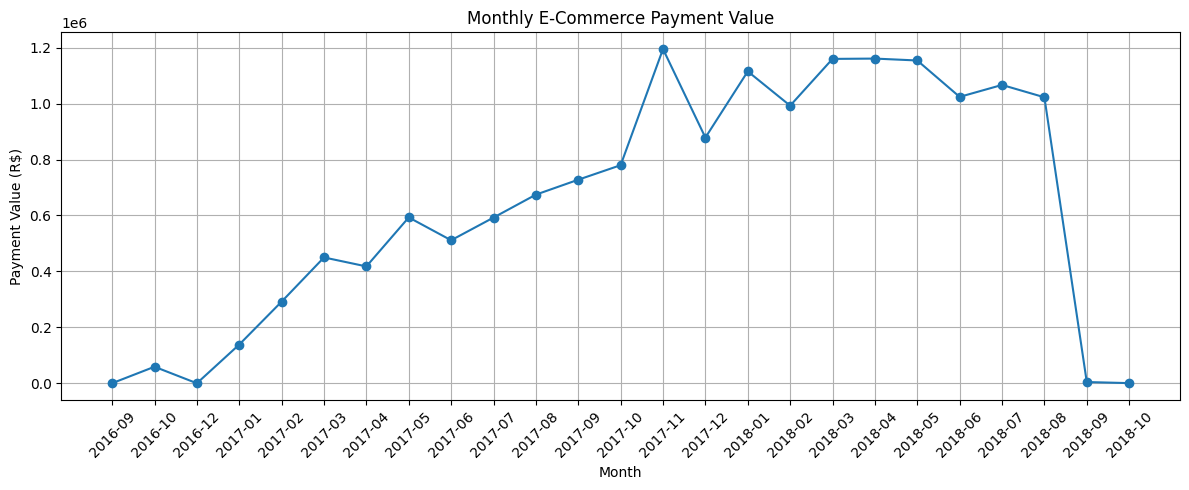

In [6]:
import matplotlib.pyplot as plt

# Create a copy of payment data joined with order purchase dates
sales = payments.merge(
    orders[["order_id", "order_purchase_timestamp", "order_status"]],
    on="order_id",
    how="left"
)

# Extract month from purchase date
sales["month"] = (
    sales["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# Calculate monthly payment value
monthly_sales = (
    sales.groupby("month")["payment_value"]
    .sum()
    .reset_index()
)

# Display results
print(monthly_sales.head(10))

# Plot monthly sales
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["month"],
    monthly_sales["payment_value"],
    marker="o"
)
plt.title("Monthly E-Commerce Payment Value")
plt.xlabel("Month")
plt.ylabel("Payment Value (R$)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Analyze product-category sales using item prices
# This avoids multiplying order payment values across multiple items.
items_products = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

top_categories = (
    items_products.groupby("product_category_name", dropna=False)["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 categories by item-price sales (freight excluded):")
print(top_categories)

top_categories.sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Product Categories by Item-Price Sales"
)

plt.xlabel("Item-price sales (R$; freight excluded)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


              transaction_records  total_payment_value
payment_type                                          
credit_card                 76795          12542084.19
boleto                      19784           2869361.27
voucher                      5775            379436.87
debit_card                   1529            217989.79
not_defined                     3                 0.00


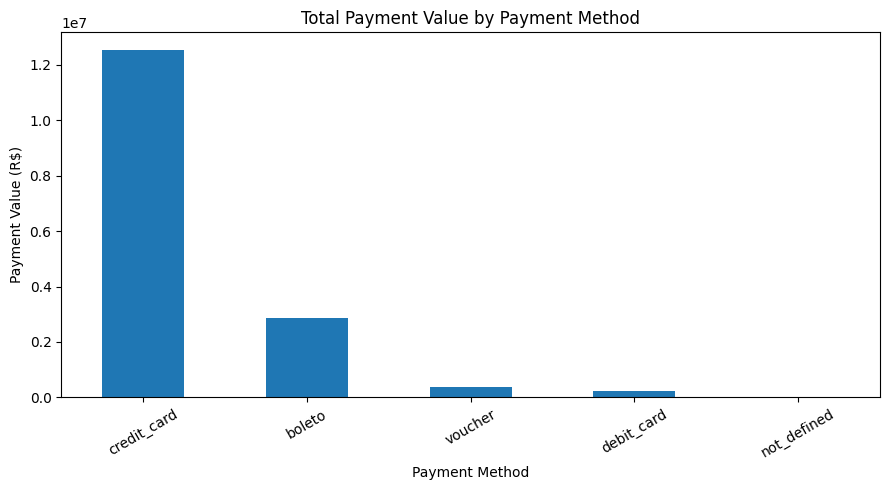

In [8]:
# Count payment records by payment method
payment_methods = (
    payments.groupby("payment_type")
    .agg(
        transaction_records=("payment_type", "size"),
        total_payment_value=("payment_value", "sum")
    )
    .sort_values("total_payment_value", ascending=False)
)

print(payment_methods)

# Plot payment value by method
payment_methods["total_payment_value"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Total Payment Value by Payment Method"
)

plt.xlabel("Payment Method")
plt.ylabel("Payment Value (R$)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Delivered orders with usable dates: 96470
Average delivery time (days): 12.56
Late orders: 7826
Late delivery percentage: 8.11 %


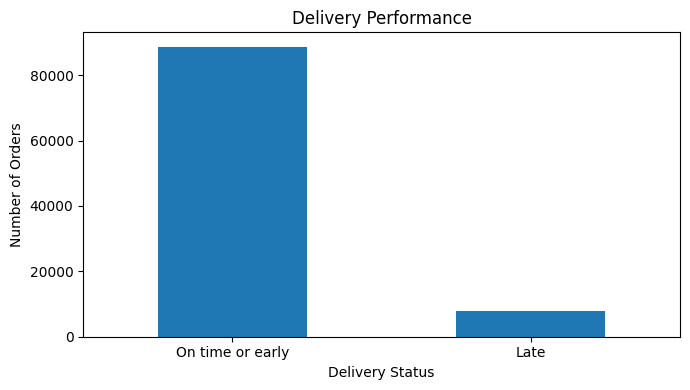

In [9]:
# Use orders with actual delivery dates
delivery = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

# Calculate actual delivery time and delay
delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery["delay_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery["late"] = delivery["delay_days"] > 0

print("Delivered orders with usable dates:", len(delivery))
print("Average delivery time (days):", round(delivery["delivery_days"].mean(), 2))
print("Late orders:", int(delivery["late"].sum()))
print("Late delivery percentage:", round(delivery["late"].mean() * 100, 2), "%")

# Plot on-time vs late
delivery["delivery_status"] = delivery["late"].map({
    True: "Late",
    False: "On time or early"
})

delivery["delivery_status"].value_counts().plot(
    kind="bar",
    figsize=(7, 4),
    title="Delivery Performance"
)

plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [10]:
import os

project_folder = "/content/ecommerce_portfolio"
os.makedirs(project_folder, exist_ok=True)

monthly_sales.to_csv(
    f"{project_folder}/monthly_sales.csv",
    index=False
)

payment_methods.to_csv(
    f"{project_folder}/payment_methods.csv"
)

delivery.to_csv(
    f"{project_folder}/delivery_analysis.csv",
    index=False
)

print("Analysis results saved!")
print("Folder:", project_folder)

Analysis results saved!
Folder: /content/ecommerce_portfolio


In [ ]:
readme = '# E-Commerce Sales Analysis and Business Insights\n\n## Project Overview\nAn exploratory data analysis project using the Brazilian E-Commerce Public Dataset by Olist. The project examines order volume, payment value, payment methods, product-category item sales, monthly trends, and delivery performance.\n\n## Business Questions\n- How many orders and unique customers are represented?\n- How does recorded payment value change by month?\n- Which payment methods account for the most payment value?\n- Which product categories have the highest item-price sales?\n- How long does delivery take, and what share of eligible delivered orders arrived late?\n\n## Key Findings\n- **Orders:** 99,441\n- **Unique customers:** 96,096 (`customer_unique_id`)\n- **Recorded payment value:** R$ 16,008,872.12\n- **Largest payment method by value:** credit card, R$ 12,542,084.19\n- **Highest payment-value month:** November 2017, R$ 1,194,882.80\n- **Average delivery time:** 12.56 days\n- **Late delivery rate:** 8.11% among delivered orders with usable actual and estimated delivery dates (96,470 orders)\n\n## Tools\n- Python\n- Pandas\n- Matplotlib\n- SQLite / SQL\n\n## Analysis Included\n1. Dataset loading and basic exploration\n2. Business KPI calculations\n3. Monthly payment-value trend\n4. Product-category sales using order-item prices\n5. Payment method analysis\n6. Delivery-time and late-delivery analysis\n7. SQL queries for order status, monthly orders, category sales, payment methods, and average order value\n\n## Project Files\n- `analysis.ipynb` — analysis notebook\n- `sql_queries.sql` — SQL business queries\n- `olist_analysis.db` — SQLite database for the main tables\n- `business_insights.txt` — key metrics\n- `monthly_sales.csv` — monthly recorded payment values\n- `payment_methods.csv` — payment-method summary\n- `delivery_analysis.csv` — delivery-level analysis output\n\n## Important Definitions and Limitations\n- Recorded payment value is **not profit**; costs and expenses are not included.\n- Product-category sales are summed from order-item `price` and **exclude freight**.\n- Delivery performance uses delivered orders with non-null actual and estimated delivery dates.\n- Missing values are not automatically removed; they should be assessed based on their meaning.\n- The Olist dataset is historical, so findings describe the dataset period, not current e-commerce performance.\n\n## Dataset\nBrazilian E-Commerce Public Dataset by Olist: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce\n'
readme_path = f"{project_folder}/README.md"
with open(readme_path, "w", encoding="utf-8") as f:
    f.write(readme)
print("README updated:", readme_path)


In [12]:
import sqlite3
import os

project_folder = "/content/ecommerce_portfolio"
os.makedirs(project_folder, exist_ok=True)

conn = sqlite3.connect(f"{project_folder}/olist_analysis.db")

tables_to_load = [
    "olist_orders_dataset",
    "olist_order_items_dataset",
    "olist_order_payments_dataset",
    "olist_customers_dataset",
    "olist_products_dataset"
]

for table in tables_to_load:
    datasets[table].to_sql(table, conn, if_exists="replace", index=False)
    print(f"Loaded: {table}")

print("SQL database created successfully!")

Loaded: olist_orders_dataset
Loaded: olist_order_items_dataset
Loaded: olist_order_payments_dataset
Loaded: olist_customers_dataset
Loaded: olist_products_dataset
SQL database created successfully!


In [13]:
query = """
SELECT order_status, COUNT(*) AS total_orders
FROM olist_orders_dataset
GROUP BY order_status
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)
print(result)

  order_status  total_orders
0    delivered         96478
1      shipped          1107
2     canceled           625
3  unavailable           609
4     invoiced           314
5   processing           301
6      created             5
7     approved             2


In [14]:
sql_queries = {
    "1. Order status analysis": """
        SELECT order_status, COUNT(*) AS total_orders
        FROM olist_orders_dataset
        GROUP BY order_status
        ORDER BY total_orders DESC;
    """,

    "2. Monthly order trends": """
        SELECT
            SUBSTR(order_purchase_timestamp, 1, 7) AS order_month,
            COUNT(*) AS total_orders
        FROM olist_orders_dataset
        WHERE order_purchase_timestamp IS NOT NULL
        GROUP BY SUBSTR(order_purchase_timestamp, 1, 7)
        ORDER BY order_month;
    """,

    "3. Top 10 product categories by sales": """
        SELECT
            p.product_category_name,
            ROUND(SUM(i.price), 2) AS product_sales
        FROM olist_order_items_dataset AS i
        JOIN olist_products_dataset AS p
            ON i.product_id = p.product_id
        GROUP BY p.product_category_name
        ORDER BY product_sales DESC
        LIMIT 10;
    """,

    "4. Payment method analysis": """
        SELECT
            payment_type,
            COUNT(*) AS payment_records,
            ROUND(SUM(payment_value), 2) AS total_payment_value
        FROM olist_order_payments_dataset
        GROUP BY payment_type
        ORDER BY total_payment_value DESC;
    """,

    "5. Average order value": """
        SELECT
            ROUND(SUM(payment_value) / COUNT(DISTINCT order_id), 2)
                AS average_order_value
        FROM olist_order_payments_dataset;
    """
}

for title, query in sql_queries.items():
    print("\n" + "=" * 50)
    print(title)
    print("=" * 50)
    display(pd.read_sql_query(query, conn))


1. Order status analysis


,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2



2. Monthly order trends


,order_month,total_orders
0,2016-09,4
1,2016-10,324
2,2016-12,1
3,2017-01,800
4,2017-02,1780
5,2017-03,2682
6,2017-04,2404
7,2017-05,3700
8,2017-06,3245
9,2017-07,4026



3. Top 10 product categories by sales


,product_category_name,product_sales
0,beleza_saude,1258681.34
1,relogios_presentes,1205005.68
2,cama_mesa_banho,1036988.68
3,esporte_lazer,988048.97
4,informatica_acessorios,911954.32
5,moveis_decoracao,729762.49
6,cool_stuff,635290.85
7,utilidades_domesticas,632248.66
8,automotivo,592720.11
9,ferramentas_jardim,485256.46



4. Payment method analysis


,payment_type,payment_records,total_payment_value
0,credit_card,76795,12542084.19
1,boleto,19784,2869361.27
2,voucher,5775,379436.87
3,debit_card,1529,217989.79
4,not_defined,3,0.00



5. Average order value


,average_order_value
0,160.99


In [15]:
sql_file = f"{project_folder}/sql_queries.sql"

with open(sql_file, "w", encoding="utf-8") as f:
    for title, query in sql_queries.items():
        f.write(f"-- {title}\n")
        f.write(query.strip() + "\n\n")

print("SQL queries saved to:", sql_file)

SQL queries saved to: /content/ecommerce_portfolio/sql_queries.sql


In [16]:
# 1. Order and customer KPIs
total_orders = orders["order_id"].nunique()
unique_customers = customers["customer_unique_id"].nunique()
total_revenue = payments["payment_value"].sum()

# 2. Top payment method
top_payment = payments.groupby("payment_type")["payment_value"].sum().idxmax()
top_payment_value = payments.groupby("payment_type")["payment_value"].sum().max()

# 3. Monthly sales: highest month
best_month_row = monthly_sales.loc[
    monthly_sales["payment_value"].idxmax()
]

# 4. Delivery performance
late_percentage = delivery["late"].mean() * 100
average_delivery_days = delivery["delivery_days"].mean()

print("===== BUSINESS INSIGHTS =====")
print(f"Total orders: {total_orders:,}")
print(f"Unique customers: {unique_customers:,}")
print(f"Total recorded payment value: {total_revenue:,.2f}")
print(f"Top payment method: {top_payment}")
print(f"Payment value for top method: {top_payment_value:,.2f}")
print(f"Highest payment-value month: {best_month_row['month']}")
print(f"Payment value in highest month: {best_month_row['payment_value']:,.2f}")
print(f"Average delivery time: {average_delivery_days:.2f} days")
print(f"Late-delivery percentage: {late_percentage:.2f}%")

===== BUSINESS INSIGHTS =====
Total orders: 99,441
Unique customers: 96,096
Total recorded payment value: 16,008,872.12
Top payment method: credit_card
Payment value for top method: 12,542,084.19
Highest payment-value month: 2017-11
Payment value in highest month: 1,194,882.80
Average delivery time: 12.56 days
Late-delivery percentage: 8.11%


In [17]:
insights = f"""
E-COMMERCE SALES ANALYSIS — KEY METRICS

Total orders: {total_orders:,}
Unique customers: {unique_customers:,}
Total recorded payment value: {total_revenue:,.2f}
Top payment method: {top_payment}
Payment value for top method: {top_payment_value:,.2f}
Highest payment-value month: {best_month_row['month']}
Payment value in highest month: {best_month_row['payment_value']:,.2f}
Average delivery time: {average_delivery_days:.2f} days
Late-delivery percentage: {late_percentage:.2f}%

Note: Payment value is not profit. Late delivery is measured against
the estimated delivery date for delivered orders with valid dates.
"""

with open(f"{project_folder}/business_insights.txt", "w", encoding="utf-8") as f:
    f.write(insights)

print("Business insights saved!")

Business insights saved!


In [18]:
insights = f"""
E-COMMERCE SALES ANALYSIS — KEY METRICS

Total orders: {total_orders:,}
Unique customers: {unique_customers:,}
Total recorded payment value: {total_revenue:,.2f}
Top payment method: {top_payment}
Payment value for top method: {top_payment_value:,.2f}
Highest payment-value month: {best_month_row['month']}
Payment value in highest month: {best_month_row['payment_value']:,.2f}
Average delivery time: {average_delivery_days:.2f} days
Late-delivery percentage: {late_percentage:.2f}%

Note: Payment value is not profit. Late delivery is measured against
the estimated delivery date for delivered orders with valid dates.
"""

with open(f"{project_folder}/business_insights.txt", "w", encoding="utf-8") as f:
    f.write(insights)

print("Business insights saved!")

Business insights saved!


In [20]:
import shutil
from google.colab import files

# Compress the portfolio folder into a ZIP file
shutil.make_archive("/content/ecommerce_portfolio", "zip", "/content/ecommerce_portfolio")

# Download the created ZIP file
files.download("/content/ecommerce_portfolio.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>